In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

# 讓圖表直接顯示在 Notebook 中
%matplotlib inline 

# 設定中文字型 (避免亂碼)
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei'] 
plt.rcParams['axes.unicode_minus'] = False

print("套件匯入完成！")

套件匯入完成！


In [ ]:
PROJECT_ROOT = "D:\\Project\\ML\\Bread_classifier"

DATA_DIR = os.path.join(PROJECT_ROOT, "data")
MODEL_SAVE_PATH = os.path.join(PROJECT_ROOT, "notebooks\\models", "bread_model_notebook.pth")

BATCH_SIZE = 32
LEARNING_RATE = 0.001
EPOCHS = 15

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"專案路徑: {PROJECT_ROOT}")
print(f"資料路徑: {DATA_DIR}")
print(f"模型儲存路徑: {MODEL_SAVE_PATH}")
print(f"使用設備: {device}")

專案路徑: D:\Project\ML\Bread_classifier
資料路徑: D:\Project\ML\Bread_classifier\data
模型儲存路徑: D:\Project\ML\Bread_classifier\notebooks\models\bread_model_notebook.pth
使用設備: cuda


In [4]:
# 資料擴增與標準化
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

print("正在讀取資料...")

# 檢查路徑是否存在
if not os.path.exists(os.path.join(DATA_DIR, 'train')):
    print(f"錯誤: 找不到訓練資料夾 {os.path.join(DATA_DIR, 'train')}")
else:
    image_datasets = {
        x: datasets.ImageFolder(os.path.join(DATA_DIR, x), data_transforms[x]) 
        for x in ['train', 'val']
    }

    dataloaders = {
        x: torch.utils.data.DataLoader(image_datasets[x], batch_size=BATCH_SIZE, shuffle=True, num_workers=0) 
        for x in ['train', 'val']
    }

    dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
    class_names = image_datasets['train'].classes

    print(f"資料載入成功！")
    print(f"類別數量: {len(class_names)} 種")
    print(f"類別清單: {class_names}")
    print(f"訓練集: {dataset_sizes['train']} 張 | 驗證集: {dataset_sizes['val']} 張")

正在讀取資料...
資料載入成功！
類別數量: 10 種
類別清單: ['danish_butter_polo', 'danish_coffee_polo', 'danish_polo', 'garlic_parsley', 'peanut_bread', 'puff_rousong', 'rousong_salad', 'walnut_brioche', 'white_bread_choc', 'white_bread_straw']
訓練集: 1049 張 | 驗證集: 258 張


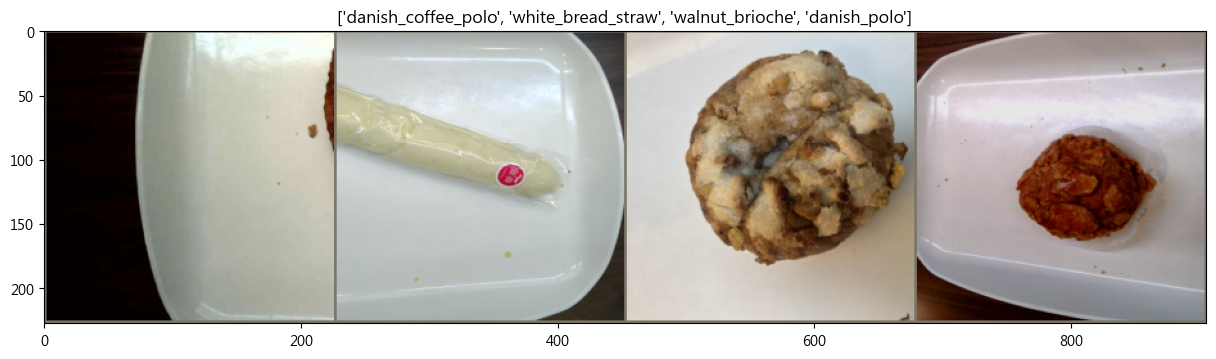

In [ ]:
import torchvision

def imshow(inp, title=None):
    """將 Tensor 轉回圖片顯示"""
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title:
        plt.title(title)
    plt.pause(0.001)

inputs, classes = next(iter(dataloaders['train']))
out = torchvision.utils.make_grid(inputs[:4]) # 只看前4張

plt.figure(figsize=(15, 5))
imshow(out, title=[class_names[x] for x in classes[:4]])

In [10]:
print("正在下載並建立 ResNet18 模型...")
model = models.resnet18(pretrained=True)

# 修改最後一層
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, len(class_names))

model = model.to(device)

# 定義損失函數與優化器
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=0.9)
exp_lr_scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)

print("模型架構建立完成。")

正在下載並建立 ResNet18 模型...


d:\anaconda3\envs\ML\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
d:\anaconda3\envs\ML\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


模型架構建立完成。


In [ ]:
print(f"開始訓練: 共 {EPOCHS} 輪")
since = time.time()

best_model_wts = copy.deepcopy(model.state_dict())
best_acc = 0.0

# 用兩個 list 來紀錄訓練過程，方便等一下畫圖分析
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    print(f'Epoch {epoch+1}/{EPOCHS}')
    print('-' * 10)

    for phase in ['train', 'val']:
        if phase == 'train':
            model.train() 
        else:
            model.eval() 

        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in dataloaders[phase]:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            with torch.set_grad_enabled(phase == 'train'):
                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                loss = criterion(outputs, labels)

                if phase == 'train':
                    loss.backward()
                    optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

        if phase == 'train':
            exp_lr_scheduler.step()

        epoch_loss = running_loss / dataset_sizes[phase]
        epoch_acc = running_corrects.double() / dataset_sizes[phase]

        print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')
        
        # 紀錄數據
        if phase == 'train':
            history['train_loss'].append(epoch_loss)
            history['train_acc'].append(epoch_acc.item())
        else:
            history['val_loss'].append(epoch_loss)
            history['val_acc'].append(epoch_acc.item())

        if phase == 'val' and epoch_acc > best_acc:
            best_acc = epoch_acc
            best_model_wts = copy.deepcopy(model.state_dict())

time_elapsed = time.time() - since
print(f'\n訓練完成！總耗時: {time_elapsed // 60:.0f}分 {time_elapsed % 60:.0f}秒')
print(f'最佳驗證準確率: {best_acc:.4f}')

# 儲存模型
os.makedirs(os.path.dirname(MODEL_SAVE_PATH), exist_ok=True)
model.load_state_dict(best_model_wts)
torch.save(model.state_dict(), MODEL_SAVE_PATH)
print(f"模型已儲存至: {MODEL_SAVE_PATH}")

In [ ]:
def plot_confusion_matrix(model, dataloader, class_names, device):
    print("\n正在計算混淆矩陣，請稍候...")
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    cm = confusion_matrix(all_labels, all_preds)

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.ylabel('真實類別 (True Label)', fontsize=14)
    plt.xlabel('預測類別 (Predicted Label)', fontsize=14)
    plt.title('混淆矩陣 (Confusion Matrix)', fontsize=16)
    plt.show()

plot_confusion_matrix(model, dataloaders['val'], class_names, device)